<a href="https://colab.research.google.com/github/isisbia/am-t5/blob/main/TreeMap_Census_Aula1027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conector de Drive e Pre-Load de Dados

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pickle
with open('/content/drive/MyDrive/am-t6/census.pkl', 'rb') as f:
  X_census_train, y_census_train, X_census_test, y_census_test = pickle.load(f)

# Provedor de Testes [25%]

In [3]:
X_census_test.shape, y_census_test.shape

((4885, 114), (4885,))

# Provedor de Treino [75%]

In [4]:
X_census_train.shape, y_census_train.shape

((27676, 114), (27676,))

# Pipeline | Construção do Algoritmo ML - TreeMap [Census]

In [5]:
!pip -q install yellowbrick
!pip -q install scikit-learn

In [6]:
from sklearn.tree import DecisionTreeClassifier

In [7]:
arvore_census = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_census.fit(X_census_train, y_census_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [8]:
DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='entropy',
                      max_depth=None, max_features=None, max_leaf_nodes=None,
                      min_impurity_decrease=0.0,
                      min_samples_leaf=1, min_samples_split=2,
                      min_weight_fraction_leaf=0.0,
                      random_state=0, splitter='best')

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [9]:
tree_predicao = arvore_census.predict(X_census_test)
tree_predicao

array([' <=50K', ' <=50K', ' <=50K', ..., ' <=50K', ' <=50K', ' >50K'],
      dtype=object)

In [10]:
y_census_test

array([' <=50K', ' <=50K', ' <=50K', ..., ' <=50K', ' <=50K', ' <=50K'],
      dtype=object)

In [11]:
from sklearn.metrics import accuracy_score, classification_report
accuracy_score(y_census_test, tree_predicao)

0.8102354145342886

0.8102354145342886

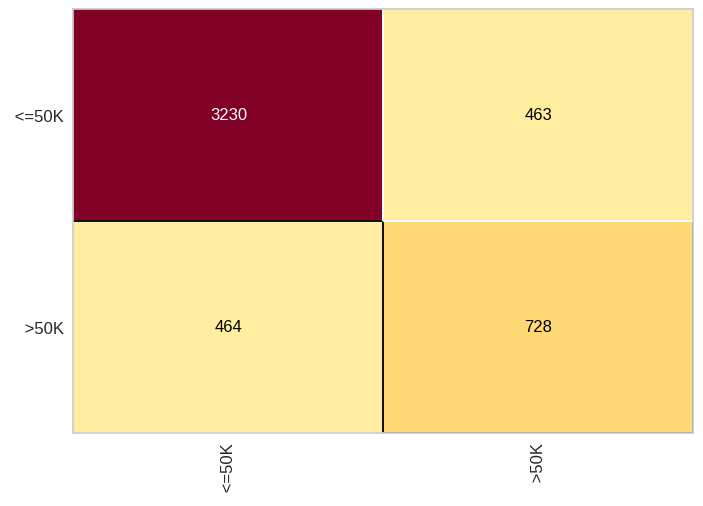

In [12]:
from yellowbrick.classifier import ConfusionMatrix
cm = ConfusionMatrix(arvore_census)
cm.fit(X_census_train, y_census_train)
cm.score(X_census_test, y_census_test)

In [13]:
print(classification_report(y_census_test, tree_predicao))

              precision    recall  f1-score   support

       <=50K       0.87      0.87      0.87      3693
        >50K       0.61      0.61      0.61      1192

    accuracy                           0.81      4885
   macro avg       0.74      0.74      0.74      4885
weighted avg       0.81      0.81      0.81      4885



In [14]:
import matplotlib.pyplot as plt
from plotly import graph_objects as go
from sklearn.tree import export_graphviz
import graphviz

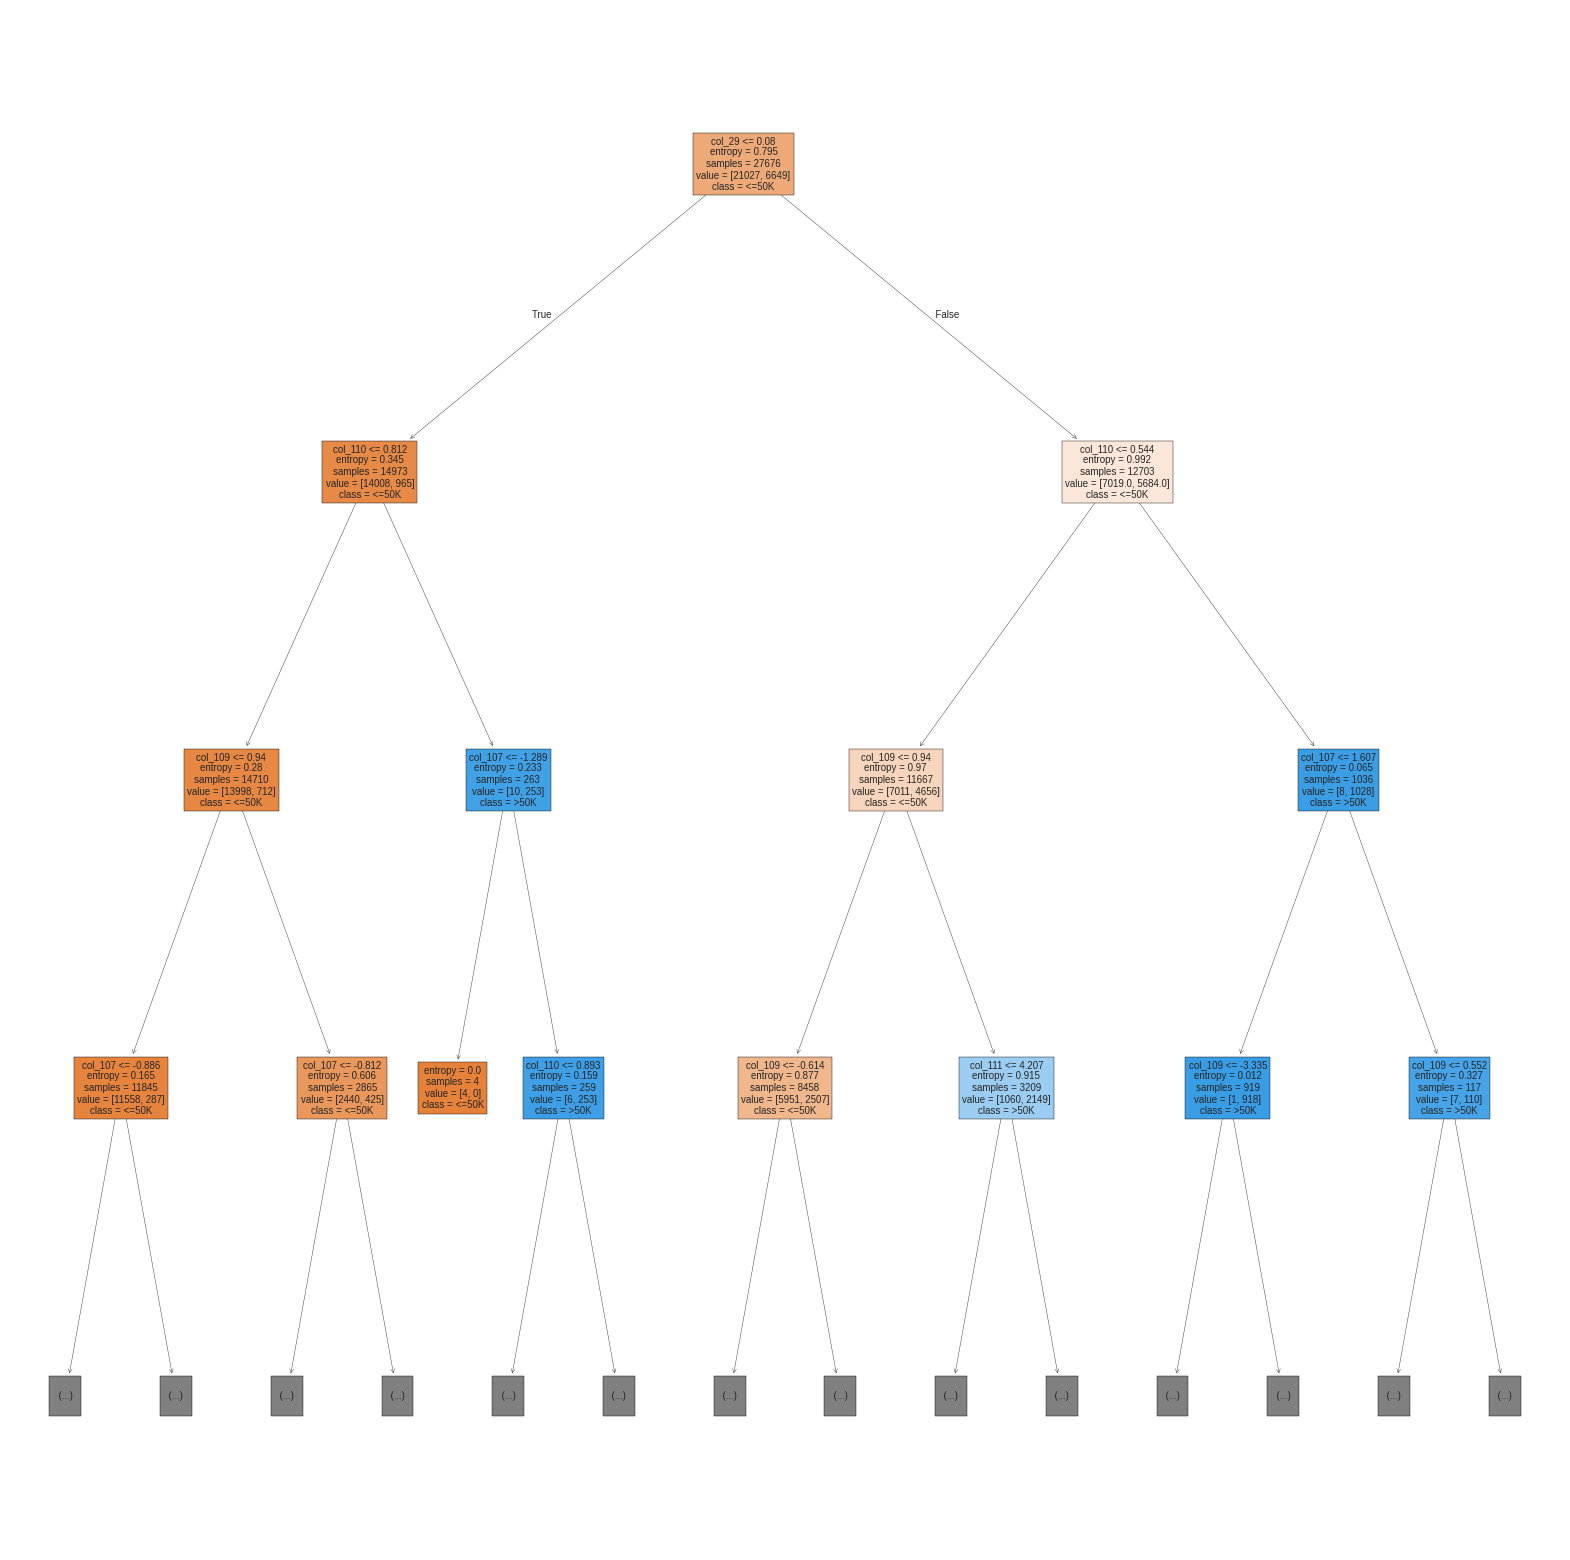

In [15]:
from sklearn import tree

total_features = X_census_train.shape[1]
feature_cols = ['age', 'workclass', 'education'] + [f'col_{i}' for i in range(2, total_features)]

class_names = ['<=50K', '>50K']

fig, axes = plt.subplots(nrows = 1, ncols = 1, figsize = (20, 20))
tree.plot_tree(arvore_census,
                feature_names = feature_cols,
                class_names = class_names,
                filled = True,
                max_depth = 3);
fig.savefig('tree_maple_sample.png')

# Pipeline | RandomForest [Credit]

In [16]:
from sklearn.ensemble import RandomForestClassifier

In [17]:
random_forest_census = RandomForestClassifier(n_estimators=40, criterion='entropy', random_state=0)
random_forest_census.fit(X_census_train, y_census_train)

RandomForestClassifier(criterion='entropy', n_estimators=40, random_state=0)

In [18]:
rf_predicoes = random_forest_census.predict(X_census_test)
rf_predicoes

array([' <=50K', ' <=50K', ' <=50K', ..., ' <=50K', ' <=50K', ' >50K'],
      dtype=object)

In [19]:
accuracy_score(y_census_test, rf_predicoes)

0.8470829068577277

0.8470829068577277

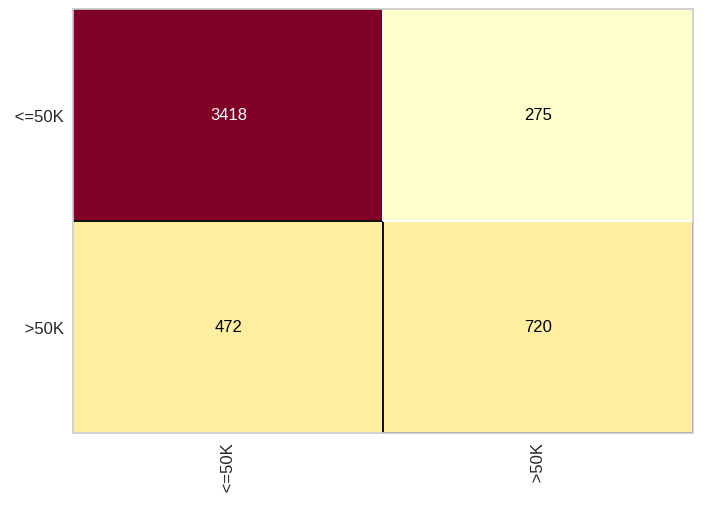

In [20]:
rf_cm = ConfusionMatrix(random_forest_census)
rf_cm.fit(X_census_train, y_census_train)
rf_cm.score(X_census_test, y_census_test)

In [21]:
print(classification_report(y_census_test, rf_predicoes))

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      3693
        >50K       0.72      0.60      0.66      1192

    accuracy                           0.85      4885
   macro avg       0.80      0.76      0.78      4885
weighted avg       0.84      0.85      0.84      4885

